In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

PROCESSED = Path("../data/processed")

artworks = pd.read_csv(PROCESSED / "artworks_clean.csv", parse_dates=["acq_date"])
artists = pd.read_csv(PROCESSED / "artists_clean.csv")
bridge = pd.read_csv(PROCESSED / "artwork_artists.csv")

print("artworks:", artworks.shape)
print("artists:", artists.shape)
print("bridge:", bridge.shape)

artworks: (130262, 18)
artists: (15091, 7)
bridge: (142176, 2)


In [2]:

credits = (
    bridge
    .merge(artworks[["artwork_id", "department", "acq_year", "acq_decade",
                     "create_year", "classification"]],
           on="artwork_id", how="left")
    .merge(artists[["artist_id", "name", "nationality", "gender", "author_type"]],
           on="artist_id", how="left")
)

print(credits.shape)
print(credits["gender"].value_counts())
credits.head()

(142176, 11)
gender
Male       113490
Female      19330
Unknown      9356
Name: count, dtype: int64


,artwork_id,artist_id,department,acq_year,acq_decade,create_year,classification,name,nationality,gender,author_type
0,2,6210,Architecture & Design,1996.0,1990.0,1896.0,Architecture,Otto Wagner,Austrian,Male,Individual
1,3,7470,Architecture & Design,1995.0,1990.0,1987.0,Architecture,Christian de Portzamparc,French,Male,Individual
2,4,7605,Architecture & Design,1997.0,1990.0,1903.0,Architecture,Emil Hoppe,Austrian,Male,Individual
3,5,7056,Architecture & Design,1995.0,1990.0,1980.0,Architecture,Bernard Tschumi,Unknown,Male,Individual
4,6,7605,Architecture & Design,1997.0,1990.0,1903.0,Architecture,Emil Hoppe,Austrian,Male,Individual


In [3]:
from scipy.stats import chi2_contingency

h1 = credits[credits["gender"].isin(["Male", "Female"]) & credits["acq_year"].notna()].copy()

h1["period"] = np.where(h1["acq_year"] < 1990, "before 1990", "1990 and later")

table = pd.crosstab(h1["period"], h1["gender"])
table = table.loc[["before 1990", "1990 and later"], ["Female", "Male"]]
print(table)

print((table["Female"] / table.sum(axis=1) * 100).round(1))

# Chi-square test
chi2, p, dof, expected = chi2_contingency(table, correction=False)
print("chi2 =", round(chi2, 1), "| p-value =", p, "| degrees of freedom =", dof)

gender          Female   Male
period                       
before 1990       4836  64631
1990 and later   13202  44713
period
before 1990        7.0
1990 and later    22.8
dtype: float64
chi2 = 6514.3 | p-value = 0.0 | degrees of freedom = 1


In [4]:

n1, f1 = table.loc["before 1990"].sum(), table.loc["before 1990", "Female"]
n2, f2 = table.loc["1990 and later"].sum(), table.loc["1990 and later", "Female"]
p1, p2 = f1 / n1, f2 / n2

diff = p2 - p1
se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)   # standard error
ci_low, ci_high = diff - 1.96 * se, diff + 1.96 * se     # 95% confidence interval

print(f"Share before 1990: {p1:.1%}")
print(f"Share 1990 and later: {p2:.1%}")
print(f"Difference: {diff * 100:.1f} percentage points")
print(f"95% CI: [{ci_low * 100:.1f}, {ci_high * 100:.1f}] percentage points")

Share before 1990: 7.0%
Share 1990 and later: 22.8%
Difference: 15.8 percentage points
95% CI: [15.4, 16.2] percentage points


In [5]:

per_year = artworks.groupby("acq_year").size()
surge_years = per_year[per_year > 3000].index
print("Surge years:", sorted(int(y) for y in surge_years))

normal = h1[~h1["acq_year"].isin(surge_years)]
table_n = pd.crosstab(normal["period"], normal["gender"]).loc[["before 1990", "1990 and later"], ["Female", "Male"]]
print(table_n)
print((table_n["Female"] / table_n.sum(axis=1) * 100).round(1))

chi2_n, p_n, _, _ = chi2_contingency(table_n, correction=False)
print("chi2 =", round(chi2_n, 1), "| p-value =", p_n)

Surge years: [1964, 1968, 1974, 2001, 2005, 2008, 2012, 2013, 2015]
gender          Female   Male
period                       
before 1990       3999  42274
1990 and later    7327  23707
period
before 1990        8.6
1990 and later    23.6
dtype: float64
chi2 = 3328.0 | p-value = 0.0


In [6]:

known = credits[credits["gender"].isin(["Female", "Male"])]
per_artist = known.groupby(["artist_id", "gender"]).size().rename("works").reset_index()

bins = [0, 1, 5, 20, np.inf]
labels = ["1 work", "2-5 works", "6-20 works", "21+ works"]
per_artist["segment"] = pd.cut(per_artist["works"], bins=bins, labels=labels)

seg_table = pd.crosstab(per_artist["segment"], per_artist["gender"])[["Female", "Male"]]
seg_table["female_pct"] = (seg_table["Female"] / (seg_table["Female"] + seg_table["Male"]) * 100).round(1)
print(seg_table)

gender      Female  Male  female_pct
segment                             
1 work        1009  4382        18.7
2-5 works      706  3034        18.9
6-20 works     304  1442        17.4
21+ works      163   923        15.0


In [7]:

two = seg_table.loc[["1 work", "21+ works"], ["Female", "Male"]]
print(two)

chi2_h3, p_h3, dof_h3, _ = chi2_contingency(two, correction=False)
print("chi2 =", round(chi2_h3, 2), "| p-value =", round(p_h3, 4), "| df =", dof_h3)

na, fa = two.loc["1 work"].sum(), two.loc["1 work", "Female"]
nb, fb = two.loc["21+ works"].sum(), two.loc["21+ works", "Female"]
pa, pb = fa / na, fb / nb
diff3 = pb - pa
se3 = np.sqrt(pa * (1 - pa) / na + pb * (1 - pb) / nb)

print(f"Share with 1 work: {pa:.1%} | with 21+ works: {pb:.1%}")
print(f"Difference: {diff3 * 100:.1f} pp, 95% CI [{(diff3 - 1.96 * se3) * 100:.1f}, {(diff3 + 1.96 * se3) * 100:.1f}]")

gender     Female  Male
segment                
1 work       1009  4382
21+ works     163   923
chi2 = 8.38 | p-value = 0.0038 | df = 1
Share with 1 work: 18.7% | with 21+ works: 15.0%
Difference: -3.7 pp, 95% CI [-6.1, -1.3]


In [8]:

chi2_all, p_all, dof_all, _ = chi2_contingency(seg_table[["Female", "Male"]], correction=False)
print("All 4 groups: chi2 =", round(chi2_all, 2), "| p-value =", round(p_all, 4), "| df =", dof_all)

All 4 groups: chi2 = 10.24 | p-value = 0.0166 | df = 3


In [9]:
from scipy.stats import normaltest, skew, mannwhitneyu, f_oneway

women = per_artist.loc[per_artist["gender"] == "Female", "works"]
men = per_artist.loc[per_artist["gender"] == "Male", "works"]

summary = per_artist.groupby("gender")["works"].agg(["count", "mean", "median", "max"]).round(1)
summary["skewness"] = per_artist.groupby("gender")["works"].apply(skew).round(1)
print(summary)

for name, x in [("Female", women), ("Male", men)]:
    stat, p = normaltest(x)
    print(name, "| normality p-value =", p)

        count  mean  median   max  skewness
gender                                     
Female   2182   8.9     2.0  3363      39.2
Male     9781  11.6     2.0  5050      40.1
Female | normality p-value = 0.0
Male | normality p-value = 0.0


In [10]:

u_stat, p_u = mannwhitneyu(women, men, alternative="two-sided")
print("Mann-Whitney U p-value =", p_u)

cles = u_stat / (len(women) * len(men))
print("Probability a random woman has more works than a random man:", round(cles, 3))

Mann-Whitney U p-value = 0.012786786245527273
Probability a random woman has more works than a random man: 0.484


In [11]:

sized = artworks.dropna(subset=["area_cm2"]).copy()
sized = sized[sized["area_cm2"] > 0]
sized["log_area"] = np.log10(sized["area_cm2"])

groups = [g["log_area"].values for _, g in sized.groupby("department") if len(g) >= 30]
f_stat, p_f = f_oneway(*groups)
print("Departments in the test:", len(groups))
print("ANOVA: F =", round(f_stat, 1), "| p-value =", p_f)

grand = sized["log_area"].mean()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
ss_total = sum(((g - grand) ** 2).sum() for g in groups)
print("eta squared =", round(ss_between / ss_total, 2))

print(sized.groupby("department")["area_cm2"].median().round(0).sort_values())

Departments in the test: 8
ANOVA: F = 3061.1 | p-value = 0.0
eta squared = 0.17
department
Fluxus Collection                         265.0
Architecture & Design - Image Archive     516.0
Photography                               608.0
Prints & Illustrated Books                611.0
Media and Performance Art                 891.0
Drawings                                 1081.0
Architecture & Design                    2029.0
Film                                     4877.0
Painting & Sculpture                     8355.0
Name: area_cm2, dtype: float64


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

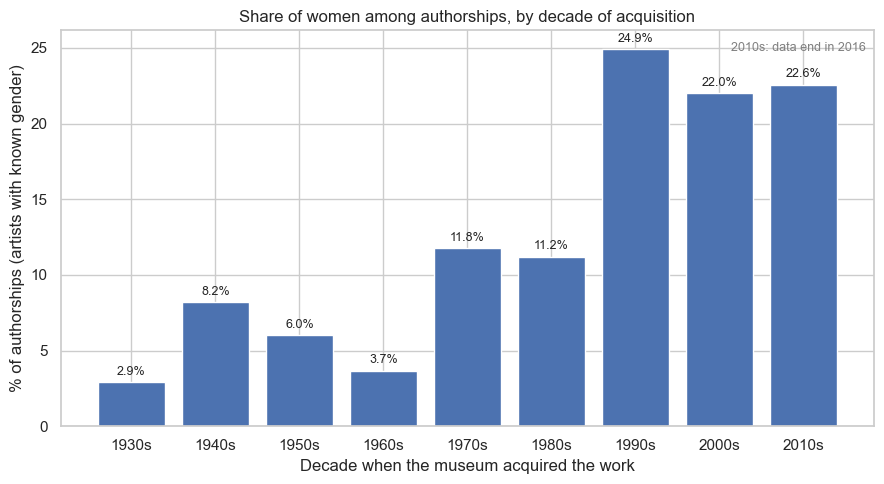

In [15]:

g = credits[credits["gender"].isin(["Female", "Male"]) & credits["acq_decade"].notna()]
by_decade = (g.groupby("acq_decade")
               .agg(credits=("gender", "size"),
                    female=("gender", lambda s: (s == "Female").sum()))
               .reset_index())
by_decade["female_pct"] = by_decade["female"] / by_decade["credits"] * 100

# Skip decades with very few authorships (the 1920s)
by_decade = by_decade[by_decade["credits"] >= 100]
by_decade["label"] = by_decade["acq_decade"].astype(int).astype(str) + "s"

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(by_decade["label"], by_decade["female_pct"], color="#4C72B0")
for x, v in zip(by_decade["label"], by_decade["female_pct"]):
    ax.text(x, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_title("Share of women among authorships, by decade of acquisition")
ax.set_xlabel("Decade when the museum acquired the work")
ax.set_ylabel("% of authorships (artists with known gender)")
ax.text(0.99, 0.97, "2010s: data end in 2016", transform=ax.transAxes,
        ha="right", va="top", fontsize=9, color="gray")
plt.tight_layout()
fig.savefig(FIG / "01_women_share_by_decade.png", dpi=200)
plt.show()

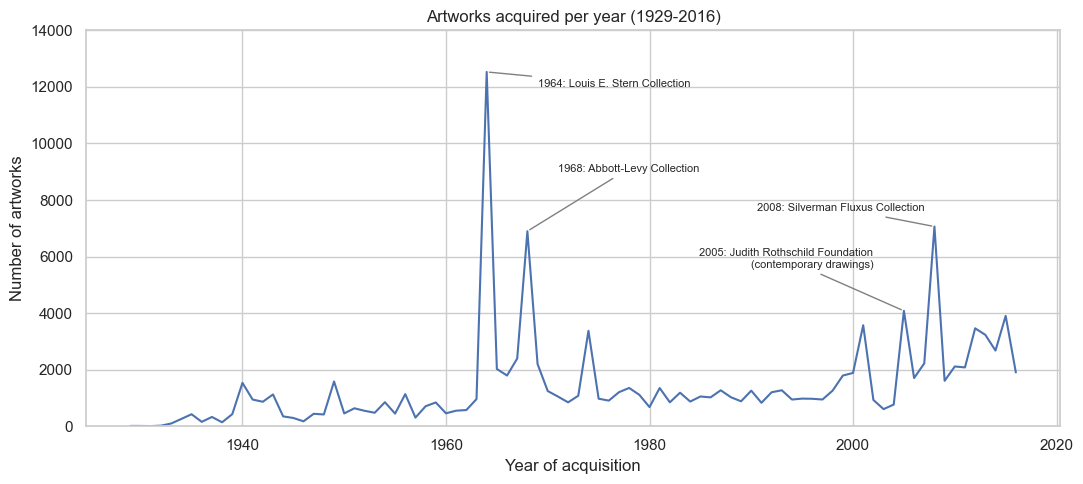

In [16]:

per_year = artworks.groupby("acq_year").size()

notes = {  # year: (label, text x, text y, alignment)
    1964: ("1964: Louis E. Stern Collection", 1969, 12000, "left"),
    1968: ("1968: Abbott-Levy Collection", 1971, 9000, "left"),
    2005: ("2005: Judith Rothschild Foundation\n(contemporary drawings)", 2002, 5600, "right"),
    2008: ("2008: Silverman Fluxus Collection", 2007, 7600, "right"),
}

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(per_year.index, per_year.values, color="#4C72B0", linewidth=1.5)
for year, (label, tx, ty, ha) in notes.items():
    ax.annotate(label, xy=(year, per_year.loc[year]), xytext=(tx, ty), ha=ha,
                fontsize=8, arrowprops=dict(arrowstyle="-", color="gray"))
ax.set_ylim(0, 14000)
ax.set_title("Artworks acquired per year (1929-2016)")
ax.set_xlabel("Year of acquisition")
ax.set_ylabel("Number of artworks")
plt.tight_layout()
fig.savefig(FIG / "02_acquisitions_per_year.png", dpi=200)
plt.show()

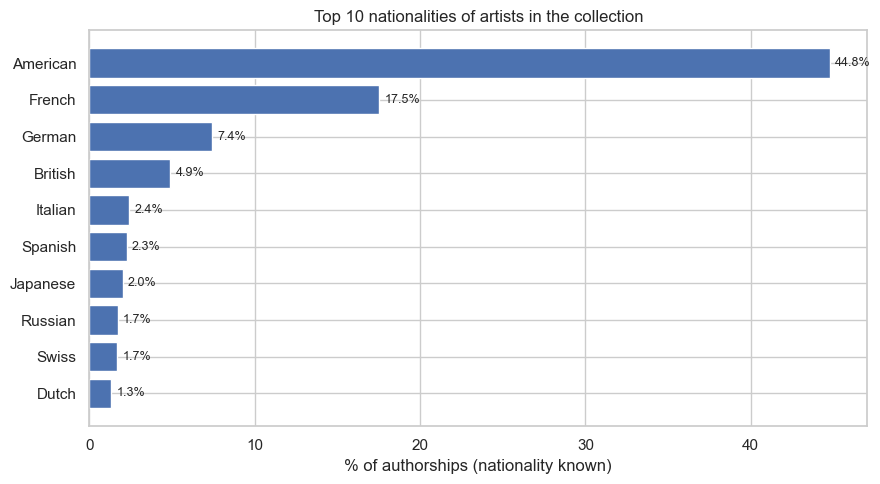

In [17]:

known_nat = credits[credits["nationality"] != "Unknown"]
top = known_nat["nationality"].value_counts().head(10)
share = (top / len(known_nat) * 100)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(share.index[::-1], share.values[::-1], color="#4C72B0")
for i, v in enumerate(share.values[::-1]):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_title("Top 10 nationalities of artists in the collection")
ax.set_xlabel("% of authorships (nationality known)")
plt.tight_layout()
fig.savefig(FIG / "03_top_nationalities.png", dpi=200)
plt.show()

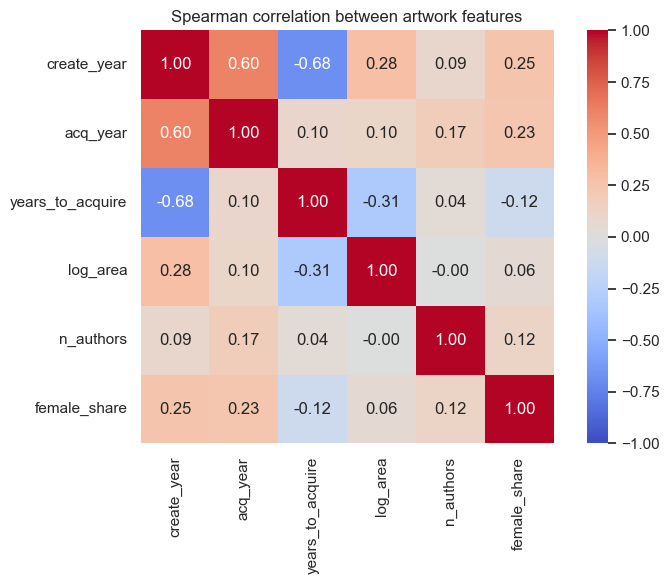

In [18]:

n_authors = bridge.groupby("artwork_id").size().rename("n_authors")

kg = credits[credits["gender"].isin(["Female", "Male"])].copy()
kg["is_female"] = (kg["gender"] == "Female").astype(int)
female_share = kg.groupby("artwork_id")["is_female"].mean().rename("female_share")

aw = artworks.set_index("artwork_id").join(n_authors).join(female_share)
aw["log_area"] = np.log10(aw["area_cm2"].where(aw["area_cm2"] > 0))

cols = ["create_year", "acq_year", "years_to_acquire", "log_area", "n_authors", "female_share"]
corr = aw[cols].corr(method="spearman")   # Spearman: works with skewed data

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Spearman correlation between artwork features")
plt.tight_layout()
fig.savefig(FIG / "04_correlation_matrix.png", dpi=200)
plt.show()

In [19]:

g = credits[credits["gender"].isin(["Female", "Male"])].copy()
g["is_female"] = g["gender"] == "Female"

g2 = g[g["create_year"].notna()].copy()
g2["create_decade"] = (g2["create_year"] // 10 * 10).astype(int)

by_create = g2.groupby("create_decade")["is_female"].agg(
    authorships="size", female_pct=lambda s: round(s.mean() * 100, 1))

print(by_create[by_create["authorships"] >= 500])

               authorships  female_pct
create_decade                         
1850                   711         0.3
1860                  1075         1.3
1870                   744         0.5
1880                   557         0.5
1890                  2540         7.7
1900                  4472         2.4
1910                  6726         6.8
1920                 11928         5.8
1930                 10855        16.4
1940                  9979         8.7
1950                  8997         8.8
1960                 21006        10.5
1970                 16203        12.8
1980                 10354        17.2
1990                  9895        34.2
2000                 10391        35.7
2010                  2810        33.8


In [20]:

for start in [1960, 1980]:
    sub = g[(g["create_year"] >= start) & g["acq_year"].notna()].copy()
    sub["period"] = np.where(sub["acq_year"] < 1990, "acquired before 1990", "acquired 1990 and later")
    t = pd.crosstab(sub["period"], sub["gender"]).loc[
        ["acquired before 1990", "acquired 1990 and later"], ["Female", "Male"]]
    pct = (t["Female"] / t.sum(axis=1) * 100).round(1)
    chi2_s, p_s, _, _ = chi2_contingency(t, correction=False)
    print(f"Works created in {start} or later")
    print(t)
    print("Share of women:", pct.to_dict())
    print("chi2 =", round(chi2_s, 1), "| p-value =", p_s)
    print()

Works created in 1960 or later
gender                   Female   Male
period                                
acquired before 1990       2413  21749
acquired 1990 and later   11470  33932
Share of women: {'acquired before 1990': 10.0, 'acquired 1990 and later': 25.3}
chi2 = 2303.8 | p-value = 0.0

Works created in 1980 or later
gender                   Female   Male
period                                
acquired before 1990        619   3741
acquired 1990 and later    9044  19640
Share of women: {'acquired before 1990': 14.2, 'acquired 1990 and later': 31.5}
chi2 = 549.5 | p-value = 1.6174664482074547e-121



In [21]:

g = credits[credits["gender"].isin(["Female", "Male"])].copy()
g["is_female"] = g["gender"] == "Female"

g3 = g[g["create_year"].notna() & g["acq_year"].notna()].copy()
g3["create_decade"] = (g3["create_year"] // 10 * 10).astype(int)
g3["period"] = np.where(g3["acq_year"] < 1990, "before_1990", "from_1990")

rows = []
for dec in [1950, 1960, 1970, 1980]:
    s = g3[g3["create_decade"] == dec]
    a = s.loc[s["period"] == "before_1990", "is_female"]
    b = s.loc[s["period"] == "from_1990", "is_female"]
    rows.append({"created_in": f"{dec}s",
                 "n_before_1990": len(a), "women_%_before": round(a.mean() * 100, 1),
                 "n_from_1990": len(b), "women_%_from_1990": round(b.mean() * 100, 1)})

print(pd.DataFrame(rows).to_string(index=False))

created_in  n_before_1990  women_%_before  n_from_1990  women_%_from_1990
     1950s           5879             6.2         2286               12.8
     1960s          13024             8.3         7432               14.5
     1970s           6778            10.6         9286               14.6
     1980s           4359            14.2         5952               19.2


In [22]:
!pip install geopandas

   ---------------------------------------- 0.0/23.8 MB ? eta -:--:--
   ----- ---------------------------------- 3.4/23.8 MB 16.3 MB/s eta 0:00:02
   ----------- ---------------------------- 6.8/23.8 MB 15.8 MB/s eta 0:00:02
   --------------- ------------------------ 9.4/23.8 MB 15.7 MB/s eta 0:00:01
   ------------------ --------------------- 11.3/23.8 MB 13.4 MB/s eta 0:00:01
   --------------------- ------------------ 12.8/23.8 MB 12.0 MB/s eta 0:00:01
   ------------------------- -------------- 15.2/23.8 MB 11.8 MB/s eta 0:00:01
   ------------------------------ --------- 18.1/23.8 MB 11.9 MB/s eta 0:00:01
   ---------------------------------- ----- 20.7/23.8 MB 12.0 MB/s eta 0:00:01
   ------------------------------------- -- 22.3/23.8 MB 11.4 MB/s eta 0:00:01
   ---------------------------------------  23.6/23.8 MB 11.2 MB/s eta 0:00:01
   ---------------------------------------- 23.8/23.8 MB 10.7 MB/s  0:00:02
   ---------------------------------------- 0.0/6.7 MB ? eta -:--:-

In [23]:
import geopandas as gpd
import urllib.request
from matplotlib.colors import LogNorm

url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
zip_path = Path("../data/raw/ne_110m_admin_0_countries.zip")
if not zip_path.exists():
    urllib.request.urlretrieve(url, zip_path)

world = gpd.read_file(zip_path)
world.columns = [c.lower() for c in world.columns]
world = world[world["name"] != "Antarctica"]     # not needed on our map
print(world.shape)
print(world[["name", "geometry"]].head(3))

(176, 169)
        name                                           geometry
0       Fiji  MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ...
1   Tanzania  POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3...
2  W. Sahara  POLYGON ((-8.66559 27.65643, -8.66512 27.58948...


In [24]:

nat_to_country = {
    "American": "United States of America", "French": "France", "German": "Germany",
    "British": "United Kingdom", "Italian": "Italy", "Spanish": "Spain", "Japanese": "Japan",
    "Russian": "Russia", "Swiss": "Switzerland", "Dutch": "Netherlands",
    "Argentine": "Argentina", "Belgian": "Belgium", "Mexican": "Mexico", "Austrian": "Austria",
    "Brazilian": "Brazil", "Canadian": "Canada", "Polish": "Poland", "Czech": "Czechia",
    "Swedish": "Sweden", "Danish": "Denmark", "Finnish": "Finland", "Israeli": "Israel",
    "Hungarian": "Hungary", "Chilean": "Chile", "Cuban": "Cuba", "Venezuelan": "Venezuela",
    "Colombian": "Colombia", "Australian": "Australia", "Chinese": "China", "Indian": "India",
    "Irish": "Ireland", "Norwegian": "Norway", "Portuguese": "Portugal", "Greek": "Greece",
    "Turkish": "Turkey", "Romanian": "Romania", "Ukrainian": "Ukraine",
    "Lithuanian": "Lithuania", "Latvian": "Latvia", "Estonian": "Estonia", "Slovak": "Slovakia",
    "Croatian": "Croatia", "Serbian": "Serbia", "Bulgarian": "Bulgaria", "Slovenian": "Slovenia",
    "Peruvian": "Peru", "Uruguayan": "Uruguay", "Ecuadorian": "Ecuador", "Bolivian": "Bolivia",
    "Paraguayan": "Paraguay", "Guatemalan": "Guatemala", "South African": "South Africa",
    "Egyptian": "Egypt", "Lebanese": "Lebanon", "Iranian": "Iran", "Nigerian": "Nigeria",
    "Moroccan": "Morocco", "Icelandic": "Iceland", "New Zealander": "New Zealand",
    "Thai": "Thailand", "Indonesian": "Indonesia", "Filipino": "Philippines",
    "Vietnamese": "Vietnam", "Taiwanese": "Taiwan", "Georgian": "Georgia",
    "Armenian": "Armenia", "Belarusian": "Belarus",
}

missing_in_map = sorted(set(nat_to_country.values()) - set(world["name"]))
print("Names not found in the map file:", missing_in_map)

known_nat = credits[credits["nationality"] != "Unknown"].copy()
known_nat["country"] = known_nat["nationality"].map(nat_to_country)
covered = known_nat["country"].notna().mean()
print(f"Authorships with a country on the map: {covered:.1%} of {len(known_nat):,}")

print(known_nat.loc[known_nat["country"].isna(), "nationality"].value_counts().head(10))

Names not found in the map file: []
Authorships with a country on the map: 97.8% of 135,887
nationality
Nationality unknown    754
Various                751
Nationality Unknown    733
Yugoslav               166
Korean                  96
Scottish                71
Costa Rican             64
Pakistani               47
Luxembourgish           44
Albanian                25
Name: count, dtype: int64


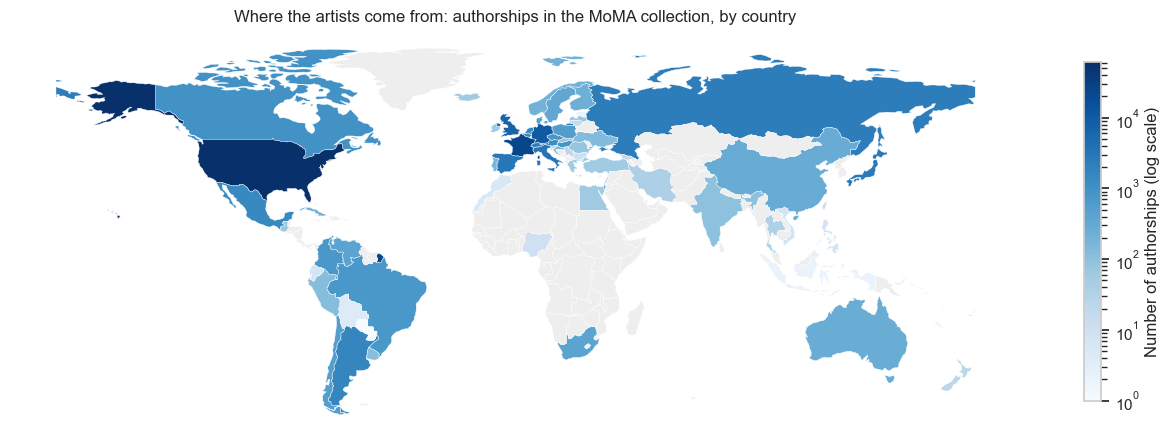

In [25]:

counts = known_nat["country"].value_counts()
world["authorships"] = world["name"].map(counts)

fig, ax = plt.subplots(figsize=(13, 6))
world.plot(
    column="authorships", cmap="Blues",
    norm=LogNorm(vmin=1, vmax=world["authorships"].max()),
    legend=True, legend_kwds={"label": "Number of authorships (log scale)", "shrink": 0.6},
    missing_kwds={"color": "#eeeeee"},
    edgecolor="white", linewidth=0.3, ax=ax)
ax.set_axis_off()
ax.set_title("Where the artists come from: authorships in the MoMA collection, by country")
plt.tight_layout()
fig.savefig(FIG / "05_map_authorships_by_country.png", dpi=200)
plt.show()

Authorships with a known nationality: 133,647
Placed on the map: 99.6%
Names not in the map file: []
nationality_clean
Yugoslav        166
Korean           96
Haitian          21
Tunisian         15
Puerto Rican     14
Zimbabwean       14
Cameroonian      13
Kenyan           12
Bosnian          10
Malian           10
Name: count, dtype: int64


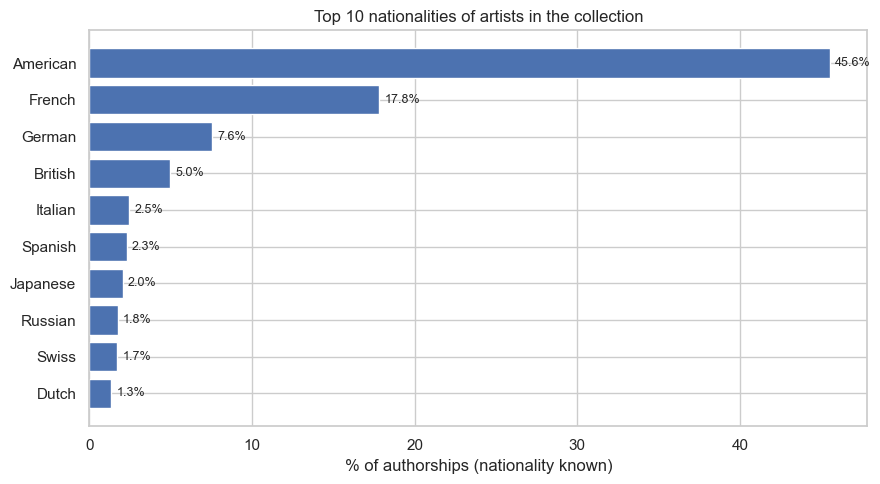

In [26]:

placeholders = ["unknown", "nationality unknown", "various"]

nat_to_country.update({
    "Scottish": "United Kingdom", "Costa Rican": "Costa Rica", "Pakistani": "Pakistan",
    "Luxembourgish": "Luxembourg", "Albanian": "Albania",
})

def add_country(df):
    low = df["nationality"].str.lower().str.strip()
    df["nationality_clean"] = df["nationality"].where(~low.isin(placeholders), "Unknown")
    df["country"] = df["nationality_clean"].map(nat_to_country)
    return df

credits = add_country(credits)
dim_artist = add_country(artists.copy())

known = credits[credits["nationality_clean"] != "Unknown"]
print(f"Authorships with a known nationality: {len(known):,}")
print(f"Placed on the map: {known['country'].notna().mean():.1%}")
print("Names not in the map file:", sorted(set(nat_to_country.values()) - set(world["name"])))
print(known.loc[known["country"].isna(), "nationality_clean"].value_counts().head(10))

top = known["nationality_clean"].value_counts().head(10)
share = top / len(known) * 100

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(share.index[::-1], share.values[::-1], color="#4C72B0")
for i, v in enumerate(share.values[::-1]):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_title("Top 10 nationalities of artists in the collection")
ax.set_xlabel("% of authorships (nationality known)")
plt.tight_layout()
fig.savefig(FIG / "03_top_nationalities.png", dpi=200)
plt.show()

In [27]:
dim_artist_out = dim_artist[["artist_id", "name", "gender", "nationality_clean", "country",
                             "author_type", "birth_year", "death_year"]]
dim_artist_out.to_csv(PROCESSED / "dim_artist.csv", index=False)
print("dim_artist:", dim_artist_out.shape)
print(dim_artist_out["country"].notna().sum(), "artists have a country on the map")

dim_artist: (15091, 8)
12165 artists have a country on the map


In [28]:
def fmt_p(p):
    return "<0.001" if p < 0.001 else f"{p:.4f}"

sn = table_n["Female"] / table_n.sum(axis=1)   # share of women, normal years only
results = pd.DataFrame([
    ["H1", "Share of women: before 1990 vs 1990 and later",
     f"{p1:.1%} -> {p2:.1%}",
     f"{diff*100:.1f} pp (95% CI {ci_low*100:.1f} to {ci_high*100:.1f})", "chi-square", fmt_p(p)],
    ["H1 check", "Same, without years with more than 3000 artworks",
     f"{sn.iloc[0]:.1%} -> {sn.iloc[1]:.1%}", "", "chi-square", fmt_p(p_n)],
    ["H3", "Share of women among artists: 1 work vs 21+ works",
     f"{pa:.1%} -> {pb:.1%}",
     f"{diff3*100:.1f} pp (95% CI {(diff3-1.96*se3)*100:.1f} to {(diff3+1.96*se3)*100:.1f})",
     "chi-square", fmt_p(p_h3)],
    ["H3 check", "Share of women across all 4 groups of artists", "", "", "chi-square", fmt_p(p_all)],
    ["Works per artist", "Women vs men",
     f"medians {women.median():.0f} vs {men.median():.0f}",
     f"P(woman has more works) = {cles:.3f}", "Mann-Whitney U", fmt_p(p_u)],
    ["Artwork size", "Area by department (log10)", "",
     f"eta squared = {ss_between / ss_total:.2f}", "ANOVA", fmt_p(p_f)],
], columns=["hypothesis", "what was tested", "values", "effect size", "test", "p-value"])

results.to_csv(PROCESSED / "analysis_results.csv", index=False)
results

,hypothesis,what was tested,values,effect size,test,p-value
0,H1,Share of women: before 1990 vs 1990 and later,7.0% -> 22.8%,15.8 pp (95% CI 15.4 to 16.2),chi-square,<0.001
1,H1 check,"Same, without years with more than 3000 artworks",8.6% -> 23.6%,,chi-square,<0.001
2,H3,Share of women among artists: 1 work vs 21+ works,18.7% -> 15.0%,-3.7 pp (95% CI -6.1 to -1.3),chi-square,0.0038
3,H3 check,Share of women across all 4 groups of artists,,,chi-square,0.0166
4,Works per artist,Women vs men,medians 2 vs 2,P(woman has more works) = 0.484,Mann-Whitney U,0.0128
5,Artwork size,Area by department (log10),,eta squared = 0.17,ANOVA,<0.001


In [29]:

extra = pd.DataFrame(
    [["H1 within decade",
      f"Works created in {r['created_in']}: acquired before 1990 vs 1990 and later",
      f"{r['women_%_before']}% -> {r['women_%_from_1990']}%",
      f"{r['women_%_from_1990'] - r['women_%_before']:.1f} pp",
      "descriptive (no test)", ""] for r in rows]
    + [["H2", "Top nationalities among authorships (nationality known)",
        f"{share.index[0]} {share.iloc[0]:.1f}%, {share.index[1]} {share.iloc[1]:.1f}%, {share.index[2]} {share.iloc[2]:.1f}%",
        "", "descriptive (no test)", ""]],
    columns=results.columns)

results_full = pd.concat([results, extra], ignore_index=True)
results_full.to_csv(PROCESSED / "analysis_results.csv", index=False)
results_full

,hypothesis,what was tested,values,effect size,test,p-value
0,H1,Share of women: before 1990 vs 1990 and later,7.0% -> 22.8%,15.8 pp (95% CI 15.4 to 16.2),chi-square,<0.001
1,H1 check,"Same, without years with more than 3000 artworks",8.6% -> 23.6%,,chi-square,<0.001
2,H3,Share of women among artists: 1 work vs 21+ works,18.7% -> 15.0%,-3.7 pp (95% CI -6.1 to -1.3),chi-square,0.0038
3,H3 check,Share of women across all 4 groups of artists,,,chi-square,0.0166
4,Works per artist,Women vs men,medians 2 vs 2,P(woman has more works) = 0.484,Mann-Whitney U,0.0128
5,Artwork size,Area by department (log10),,eta squared = 0.17,ANOVA,<0.001
6,H1 within decade,Works created in 1950s: acquired before 1990 v...,6.2% -> 12.8%,6.6 pp,descriptive (no test),
7,H1 within decade,Works created in 1960s: acquired before 1990 v...,8.3% -> 14.5%,6.2 pp,descriptive (no test),
8,H1 within decade,Works created in 1970s: acquired before 1990 v...,10.6% -> 14.6%,4.0 pp,descriptive (no test),
9,H1 within decade,Works created in 1980s: acquired before 1990 v...,14.2% -> 19.2%,5.0 pp,descriptive (no test),
